# JS11 - Lab 1
## Cats vs. Dogs Classification with CNN

Pada praktikum ini dibangun model **Convolutional Neural Network** sederhana untuk klasifikasi
citra biner kucing dan anjing. Dataset terdiri dari 4.000 citra latih per kelas dan 1.000 citra
uji per kelas, ditambah dua citra untuk pengujian satu gambar.

Alur pengerjaan mengikuti job sheet: preprocessing dan augmentasi data, pembangunan arsitektur
CNN, pelatihan 25 epoch, prediksi satu citra, lalu evaluasi pada data uji.

Catatan kompatibilitas: job sheet memakai `ImageDataGenerator` dari `keras.preprocessing.image`.
API tersebut sudah dihapus pada Keras 3, sehingga pipeline yang setara dibangun dengan
`image_dataset_from_directory` ditambah layer augmentasi. Operasinya tetap sama: normalisasi
piksel 1/255, shear 0.2, zoom 0.2, dan horizontal flip.

### Step 1 - Import Libraries

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
keras.utils.set_random_seed(SEED)

### Step 2 - Data Preprocessing

Direktori dataset berisi `training_set` dan `test_set`, masing-masing dengan subfolder `cats`
dan `dogs`. Label dibaca otomatis dari nama subfolder secara alfabetis, sehingga `cats` menjadi
kelas 0 dan `dogs` kelas 1. Urutan ini penting karena output model hanya satu nilai sigmoid:
nilai di bawah 0.5 berarti kucing dan di atas atau sama dengan 0.5 berarti anjing.

Augmentasi hanya diterapkan pada data latih. Data uji hanya dinormalisasi, karena augmentasi
pada data uji akan mengubah distribusi evaluasi.

In [2]:
BASE_DIR = 'dataset/dataset'
IMG_SIZE = (64, 64)
BATCH_SIZE = 32

train_raw = keras.utils.image_dataset_from_directory(
    f'{BASE_DIR}/training_set',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True,
    seed=SEED,
)

test_raw = keras.utils.image_dataset_from_directory(
    f'{BASE_DIR}/test_set',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False,
)

print('class_names:', train_raw.class_names)
print('Jumlah batch latih:', len(train_raw))
print('Jumlah batch uji  :', len(test_raw))

Found 8000 files belonging to 2 classes.


Found 2000 files belonging to 2 classes.


class_names: ['cats', 'dogs']
Jumlah batch latih: 250
Jumlah batch uji  : 63


Pipeline augmentasi dan normalisasi dibangun sebagai layer Keras, lalu dipetakan ke dataset.
Hasilnya dicek dari shape dan rentang nilai piksel.

In [3]:
AUTOTUNE = tf.data.AUTOTUNE

train_augmentation = keras.Sequential(
    [
        layers.Rescaling(1.0 / 255),
        layers.RandomShear(0.2),
        layers.RandomZoom(0.2),
        layers.RandomFlip('horizontal'),
    ],
    name='train_augmentation',
)


def preprocess_train(images, labels):
    return train_augmentation(images, training=True), labels


def preprocess_test(images, labels):
    return layers.Rescaling(1.0 / 255)(images), labels


training_set = train_raw.map(preprocess_train, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_set = test_raw.map(preprocess_test, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

images, labels = next(iter(training_set))
print('Shape batch citra :', images.shape)
print('Shape batch label :', labels.shape)
print('Rentang piksel    :', float(images.numpy().min()), 'sampai', float(images.numpy().max()))

Shape batch citra : (32, 64, 64, 3)
Shape batch label : (32, 1)
Rentang piksel    : 0.0 sampai 1.0


Contoh citra latih beserta labelnya. Augmentasi acak akan menggeser, memperbesar, dan membalik
citra pada setiap epoch, sehingga model tidak menghafal posisi objek.

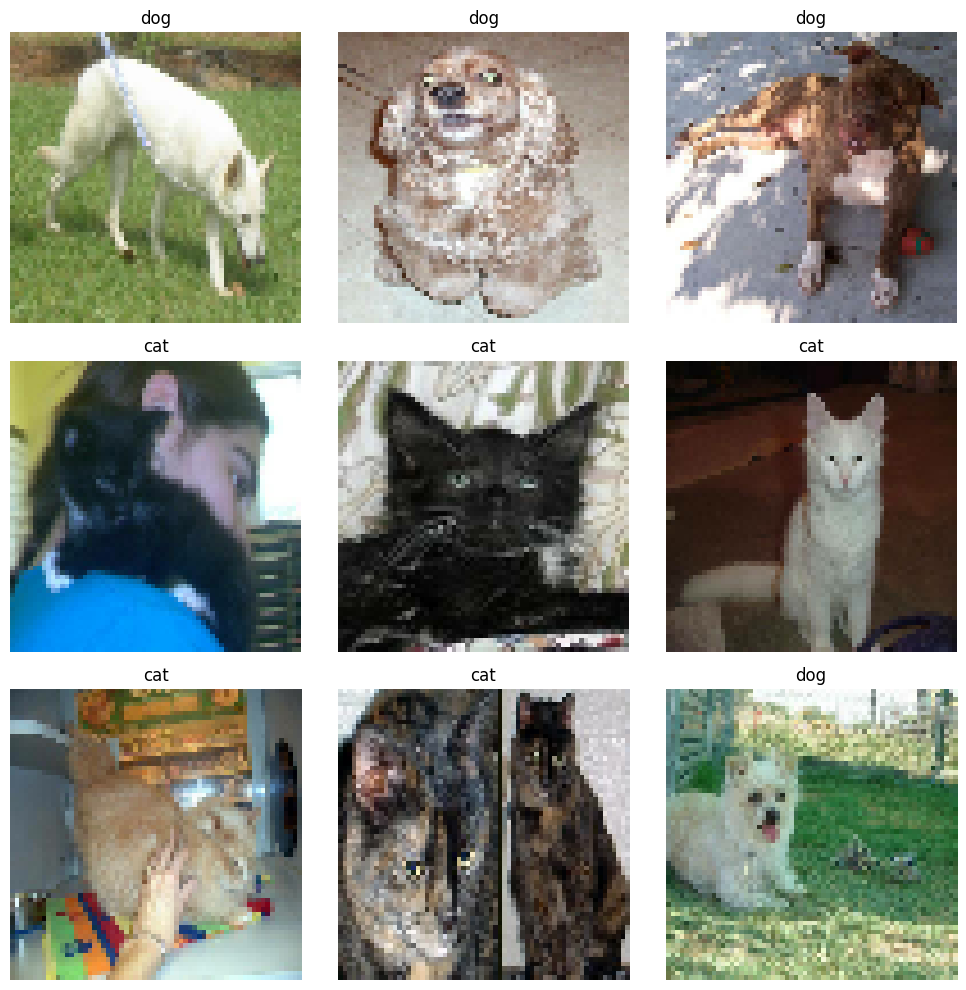

In [4]:
plt.figure(figsize=(10, 10))
for images, labels in train_raw.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title('dog' if labels[i].numpy()[0] == 1 else 'cat')
        plt.axis('off')
plt.tight_layout()
plt.show()

### Step 3 - Construction of the CNN Model

Arsitektur mengikuti job sheet:

1. **Convolutional layer 1**, 32 kernel 3x3 dengan ReLU. Layer ini mengekstrak fitur sederhana
   seperti tepi dan tekstur.
2. **Max pooling 1**, 2x2 dengan stride 2. Resolusi spasial diperkecil setengahnya.
3. **Convolutional layer 2**, 32 kernel 3x3 dengan ReLU. Fitur yang dipelajari lebih kompleks.
4. **Max pooling 2**, 2x2 dengan stride 2.
5. **Flatten**, mengubah peta fitur menjadi vektor satu dimensi.
6. **Dense 128 neuron ReLU**, bagian fully connected untuk klasifikasi.
7. **Dense 1 neuron sigmoid**, output probabilitas kelas anjing.

Karena masalahnya biner, loss yang dipakai adalah `binary_crossentropy`.

In [5]:
cnn = keras.Sequential(name='cats_vs_dogs_cnn')

cnn.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))
cnn.add(layers.MaxPool2D(pool_size=2, strides=2))
cnn.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(layers.MaxPool2D(pool_size=2, strides=2))
cnn.add(layers.Flatten())
cnn.add(layers.Dense(units=128, activation='relu'))
cnn.add(layers.Dense(units=1, activation='sigmoid'))

cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()

D:\laragon\bin\python\python-3.10\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "cats_vs_dogs_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

### Step 4 - Fit the CNN

Pelatihan dilakukan selama 25 epoch dengan `test_set` sebagai `validation_data`, sama seperti
job sheet. Perlu dicatat bahwa data validasi di sini adalah data uji yang sama, sehingga kurva
validasi sekaligus menjadi estimasi performa akhir. Evaluasi terpisah tetap dilakukan di
Step 6 untuk memastikan angka yang dilaporkan.

In [6]:
start = time.time()
history = cnn.fit(x=training_set, validation_data=test_set, epochs=25, verbose=2)
elapsed = time.time() - start

print(f'Waktu pelatihan: {elapsed:.1f} detik ({elapsed / 60:.1f} menit)')

Epoch 1/25


250/250 - 19s - 77ms/step - accuracy: 0.5947 - loss: 0.6627 - val_accuracy: 0.6950 - val_loss: 0.5934


Epoch 2/25


250/250 - 16s - 63ms/step - accuracy: 0.6779 - loss: 0.5953 - val_accuracy: 0.6875 - val_loss: 0.6046


Epoch 3/25


250/250 - 16s - 63ms/step - accuracy: 0.7048 - loss: 0.5668 - val_accuracy: 0.6810 - val_loss: 0.6396


... (41 outputs left out)

250/250 - 15s - 62ms/step - accuracy: 0.8324 - loss: 0.3749 - val_accuracy: 0.8090 - val_loss: 0.4435


Epoch 25/25


250/250 - 15s - 61ms/step - accuracy: 0.8366 - loss: 0.3668 - val_accuracy: 0.8040 - val_loss: 0.4481


Waktu pelatihan: 414.4 detik (6.9 menit)


Kurva akurasi dan loss memperlihatkan apakah model masih belajar atau sudah mulai overfitting.
Jika akurasi latih terus naik sementara akurasi validasi mendatar atau turun, model mulai
menghafal data latih.

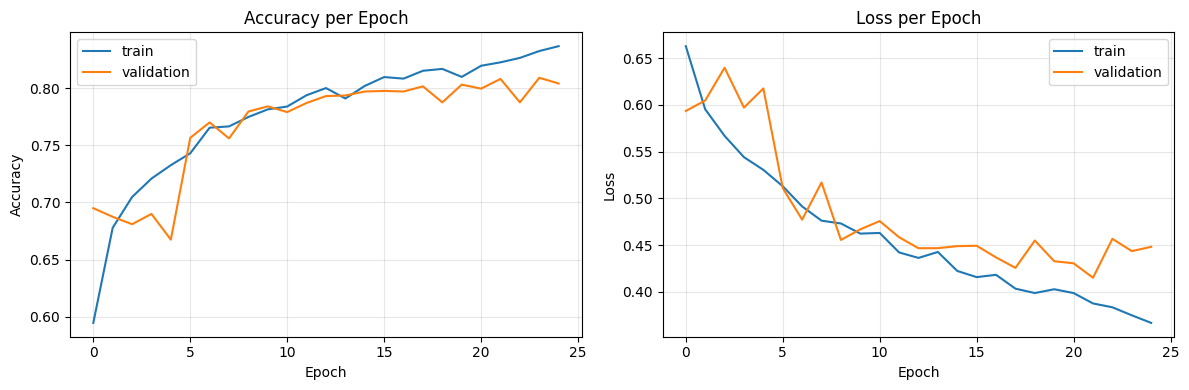

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='validation')
axes[0].set_title('Accuracy per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='validation')
axes[1].set_title('Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 5 - Prediction with a Single Image

Citra dimuat dengan ukuran 64x64, diubah ke array, lalu ditambah satu dimensi batch. Output
sigmoid dibandingkan dengan 0.5 dan dipetakan memakai `class_indices` dari data latih.

dataset/dataset/single_prediction/cat_or_dog_1.jpg -> dog (probabilitas dog = 1.0000)


dataset/dataset/single_prediction/cat_or_dog_2.jpg -> cat (probabilitas dog = 0.0000)


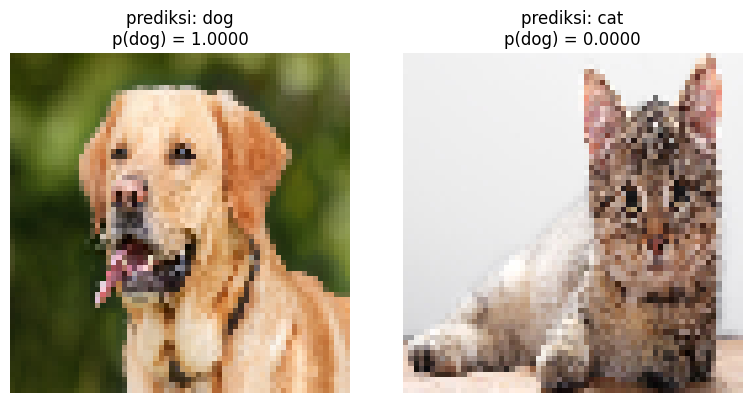

In [8]:
def predict_image(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)
    prob = float(cnn.predict(arr, verbose=0)[0][0])
    label = 'dog' if prob >= 0.5 else 'cat'
    return img, label, prob


single_dir = f'{BASE_DIR}/single_prediction'
paths = [f'{single_dir}/cat_or_dog_1.jpg', f'{single_dir}/cat_or_dog_2.jpg']

plt.figure(figsize=(8, 4))
for i, path in enumerate(paths):
    img, label, prob = predict_image(path)
    print(f'{path} -> {label} (probabilitas dog = {prob:.4f})')
    ax = plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(f'prediksi: {label}\np(dog) = {prob:.4f}')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Step 6 - Evaluation on the Test Set

Evaluasi memakai seluruh 2.000 citra uji, 1.000 per kelas. Selain akurasi total, dihitung
confusion matrix dan metrik per kelas untuk melihat apakah model lebih condong ke salah satu
kelas.

In [9]:
test_loss, test_acc = cnn.evaluate(test_set, verbose=0)
print(f'Test loss     : {test_loss:.4f}')
print(f'Test accuracy : {test_acc:.4f}')

Test loss     : 0.4481
Test accuracy : 0.8040


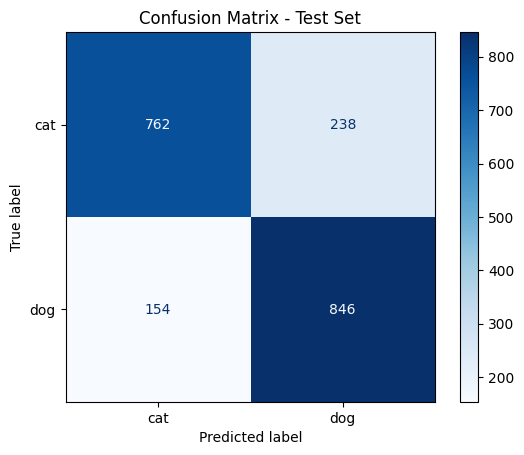

              precision    recall  f1-score   support

         cat     0.8319    0.7620    0.7954      1000
         dog     0.7804    0.8460    0.8119      1000

    accuracy                         0.8040      2000
   macro avg     0.8062    0.8040    0.8037      2000
weighted avg     0.8062    0.8040    0.8037      2000



In [10]:
y_true, y_prob = [], []

for images, labels in test_set:
    y_prob.extend(cnn.predict(images, verbose=0).ravel())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['cat', 'dog'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Test Set')
plt.show()

print(classification_report(y_true, y_pred, target_names=['cat', 'dog'], digits=4))

In [11]:
for cls, name in enumerate(['cat', 'dog']):
    mask = y_true == cls
    print(f'Akurasi kelas {name:3s}: {accuracy_score(y_true[mask], y_pred[mask]):.4f} '
          f'({mask.sum()} citra)')

Akurasi kelas cat: 0.7620 (1000 citra)
Akurasi kelas dog: 0.8460 (1000 citra)


Contoh prediksi pada sembilan citra uji acak. Judul hijau berarti prediksi benar dan judul
merah berarti salah.

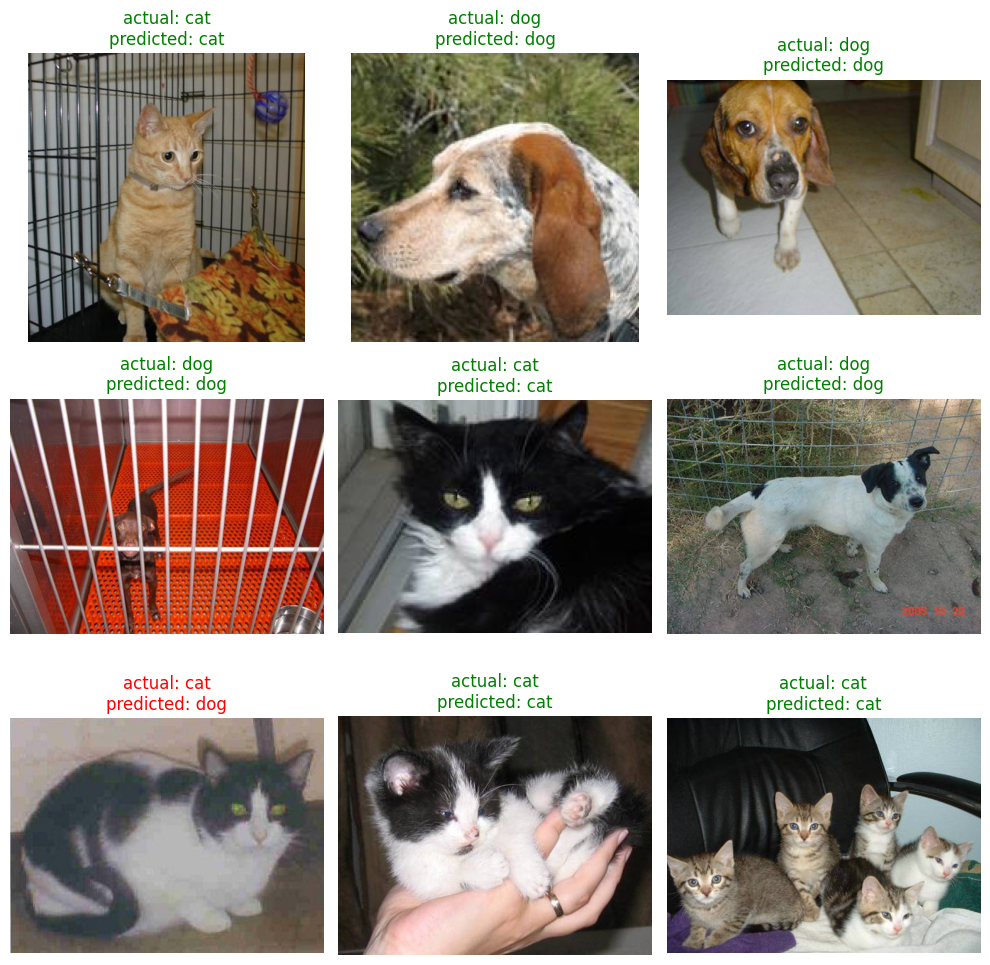

In [12]:
rng = np.random.default_rng(SEED)
indices = rng.choice(len(test_raw.file_paths), size=9, replace=False)

plt.figure(figsize=(10, 10))
for i, idx in enumerate(indices):
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(plt.imread(test_raw.file_paths[idx]))
    actual = 'dog' if y_true[idx] == 1 else 'cat'
    predicted = 'dog' if y_pred[idx] == 1 else 'cat'
    color = 'green' if actual == predicted else 'red'
    ax.set_title(f'actual: {actual}\npredicted: {predicted}', color=color)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Conclusion

Pelatihan berjalan 25 epoch selama 6.9 menit dan berhenti dengan akurasi uji **0.8040**
pada 2.000 citra, setara 1.608 prediksi benar dan 392 salah. Loss uji 0.4481.

Beberapa hal yang terlihat dari hasil:

1. **Akurasi latih lebih tinggi dari akurasi uji** (0.8366 berbanding 0.8040). Jarak sekitar
   3 poin persen ini wajar untuk CNN kecil tanpa dropout, dan belum tergolong overfitting berat.
   Augmentasi shear, zoom, dan flip sudah menahan model dari menghafal data latih.
2. **Model lebih condong ke kelas dog**. Recall dog 0.8460, sedangkan recall cat hanya 0.7620.
   Precision cat 0.8319 lebih tinggi dari precision dog 0.7804. Artinya model cenderung
   memprediksi dog ketika ragu, sehingga banyak citra cat yang salah diklasifikasi sebagai dog.
   Ketidakseimbangan ini muncul meski jumlah data kedua kelas sama, jadi penyebabnya bukan
   distribusi data melainkan fitur yang dipelajari model.
3. **Akurasi validasi mendatar sejak epoch 14** dan bergerak naik turun di kisaran 0.787 sampai
   0.809 tanpa tren naik yang jelas. Pelatihan tambahan tidak lagi memberi perbaikan berarti.
4. **Prediksi satu citra** memberi hasil yang sangat percaya diri: `cat_or_dog_1.jpg` diprediksi
   dog dengan probabilitas 1.0000 dan `cat_or_dog_2.jpg` diprediksi cat dengan probabilitas dog
   0.0000. Nilai yang menempel di 0 dan 1 menandakan output sigmoid sudah jenuh, yang konsisten
   dengan model yang cukup yakin pada data mudah.

Untuk menaikkan akurasi, langkah paling masuk akal adalah menambah convolutional layer ketiga,
menambahkan dropout sebelum dense layer, dan memakai `padding='same'` agar informasi tepi citra
tidak hilang terlalu cepat. Percobaan tersebut tidak dilakukan di Lab 1 karena job sheet meminta
arsitektur persis seperti yang tertulis.